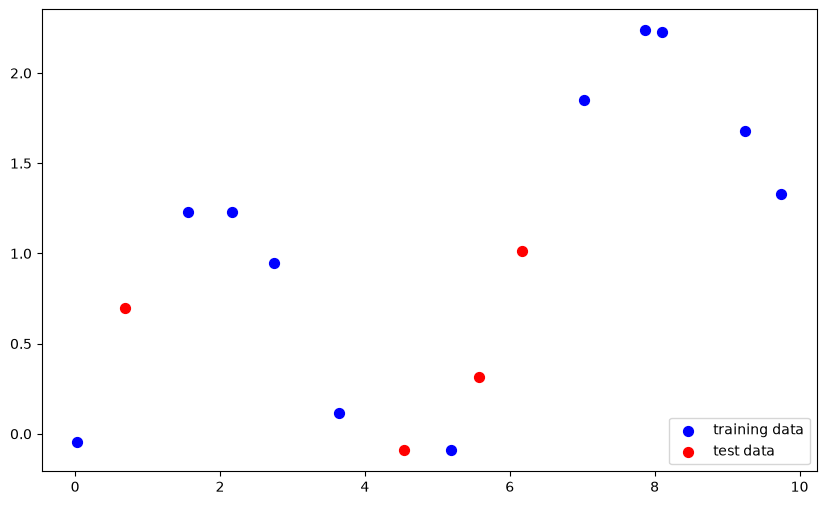

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(seed=0)
n = 15
x = np.linspace(0,10,n) + rng.standard_normal(n)/5
y = np.sin(x)+x/6 + rng.standard_normal(n)/10

X_train, X_test, y_train, y_test = train_test_split(x, y, random_state=0)

fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(X_train, y_train, label='training data', c='blue', s=50)
ax.scatter(X_test, y_test, label='test data', c='red', s=50)
ax.legend(loc=4)

### Polynomial Features
Question

Write a function that fits a polynomial LinearRegression model on the training data X_train for degrees 1, 3, 6, and 9. (Use PolynomialFeatures in sklearn.preprocessing to create the polynomial features and then fit a linear regression model) For each model, find 100 predicted values over the interval x = 0 to 10 (e.g. np.linspace(0,10,100)) and store this in a numpy array. The first row of this array should correspond to the output from the model trained on degree 1, the second row degree 3, the third row degree 6, and the fourth row degree 9.

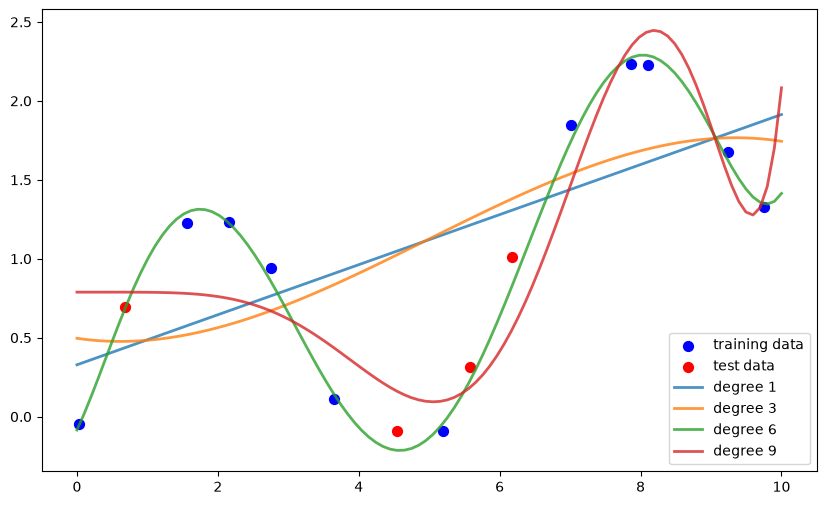

In [142]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

degrees = [1, 3, 6, 9]

# samples to test model
X_sample = np.linspace(0,10,100)

# store predictions, 4 degrees x 100 target values
predictions = np.zeros((4, 100))

for i, deg in enumerate(degrees):
    # set transformer
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    
    # fit and transform test data and fit model
    X_tr_poly = poly.fit_transform(X_train.reshape(-1,1))
    model = LinearRegression().fit(X_tr_poly, y_train)

    # test model predictions
    X_sample_poly = poly.transform(X_sample.reshape(-1,1))
    y_pred = model.predict(X_sample_poly)

    # update prdictions with y_pred
    predictions[i] = y_pred


# plot prediction boundary
for i, deg in enumerate(degrees):
    ax.plot(X_sample, predictions[i], alpha=0.8, lw=2, label=f'degree {deg}')
ax.legend(loc=4)
display(fig)